# Sleep Health and Lifestyle Prediction

##  Project Overview
In this project, we analyze the "Sleep Health and Lifestyle Dataset" to explore the relationship between daily habits (physical activity, stress, BMI) and sleep quality. Finally, we build a Machine Learning model to predict the presence of sleep disorders.

In [1]:
import pandas as pd

file_path = r"C:\Users\shira\OneDrive\שולחן העבודה\Sleep project\Sleep_health_and_lifestyle_dataset.csv"

df = pd.read_csv(file_path)

display(df.head())

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


## Step 1: Data Cleaning & Preprocessing
Preparing the data for analysis by splitting the blood pressure column and standardizing the BMI categories.

In [3]:
df['Sleep Disorder'].value_counts(dropna=False)

Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [4]:
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('Healthy')

In [5]:
df['Sleep Disorder'].value_counts()

Sleep Disorder
Healthy        219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [6]:

df['BMI Category'] = df['BMI Category'].replace('Normal Weight', 'Normal')

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,Healthy
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,Healthy
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,Healthy
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [7]:
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)

df = df.drop(columns=['Blood Pressure'])

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,Healthy,126,83
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,Healthy,125,80
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,Healthy,125,80
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


## Step 2: Exploratory Data Analysis (EDA)
Visualizing the relationships between lifestyle factors, stress, and sleep quality.

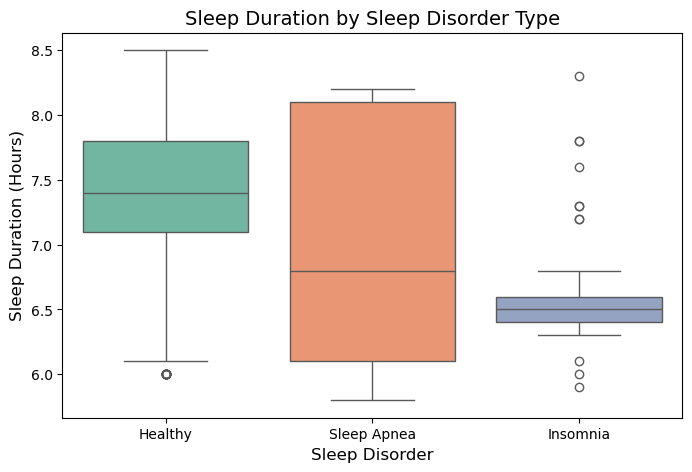

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Sleep Disorder', y='Sleep Duration', data=df, hue='Sleep Disorder', legend=False, palette='Set2')

plt.title('Sleep Duration by Sleep Disorder Type', fontsize=14)
plt.xlabel('Sleep Disorder', fontsize=12)
plt.ylabel('Sleep Duration (Hours)', fontsize=12)

plt.show()

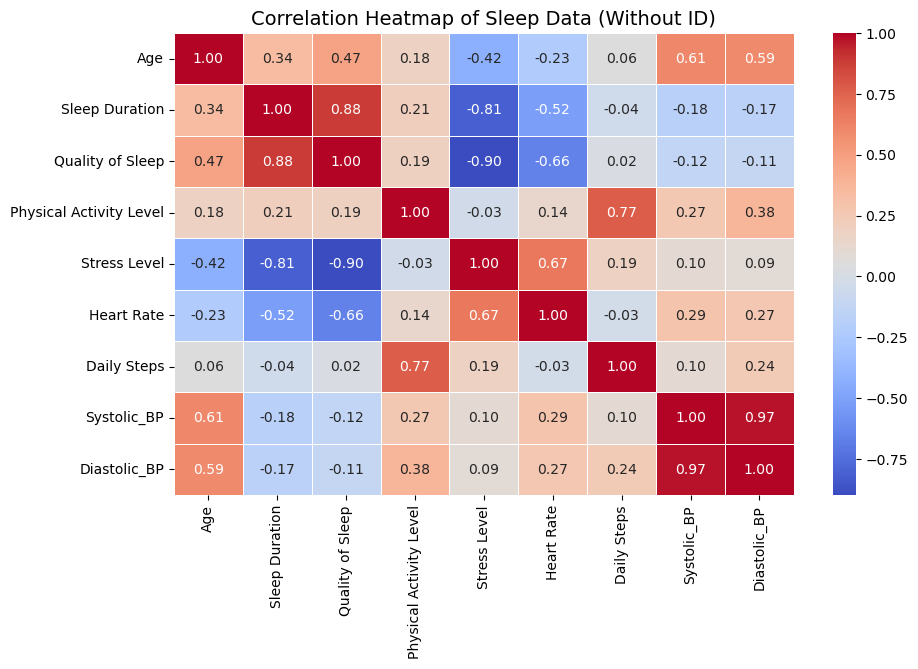

In [9]:
if 'Person ID' in df.columns:
    df = df.drop(columns=['Person ID'])

plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap of Sleep Data (Without ID)', fontsize=14)
plt.show()

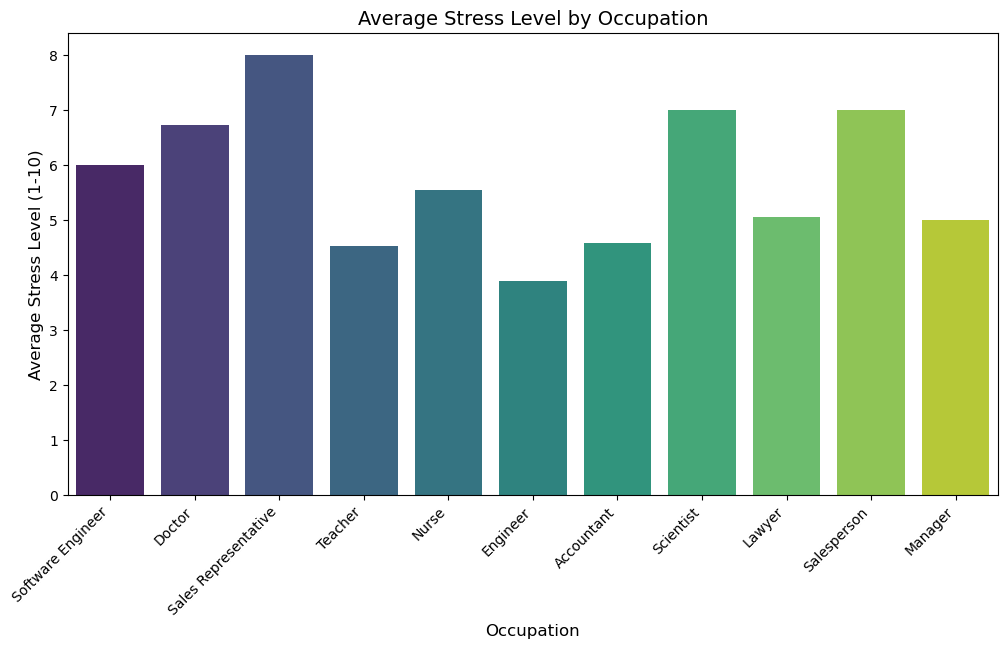

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(x='Occupation', y='Stress Level', data=df, hue='Occupation', legend=False, errorbar=None, palette='viridis')

plt.title('Average Stress Level by Occupation', fontsize=14)
plt.xlabel('Occupation', fontsize=12)
plt.ylabel('Average Stress Level (1-10)', fontsize=12)

plt.xticks(rotation=45, ha='right')

plt.show()

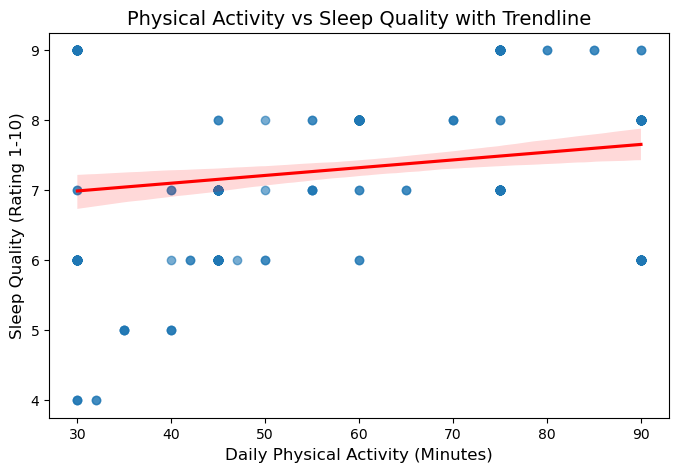

In [11]:
plt.figure(figsize=(8, 5))

sns.regplot(
    x='Physical Activity Level', 
    y='Quality of Sleep', 
    data=df, 
    scatter_kws={'alpha': 0.6}, 
    line_kws={'color': 'red'}   
)

plt.title('Physical Activity vs Sleep Quality with Trendline', fontsize=14)
plt.xlabel('Daily Physical Activity (Minutes)', fontsize=12)
plt.ylabel('Sleep Quality (Rating 1-10)', fontsize=12)

plt.show()

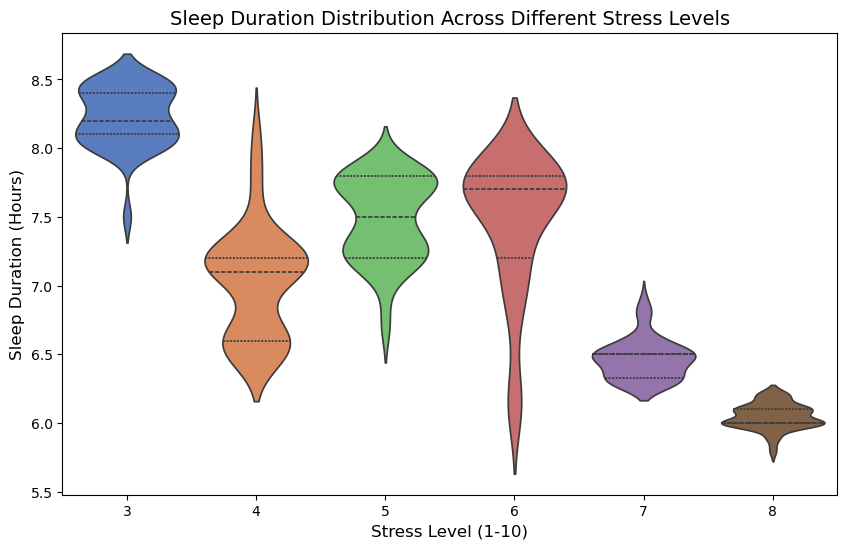

In [12]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    x='Stress Level',
    y='Sleep Duration',
    data=df,
    hue='Stress Level',
    legend=False,
    palette='muted',
    inner='quartile'
)

plt.title('Sleep Duration Distribution Across Different Stress Levels', fontsize=14)
plt.xlabel('Stress Level (1-10)', fontsize=12)
plt.ylabel('Sleep Duration (Hours)', fontsize=12)

plt.show()

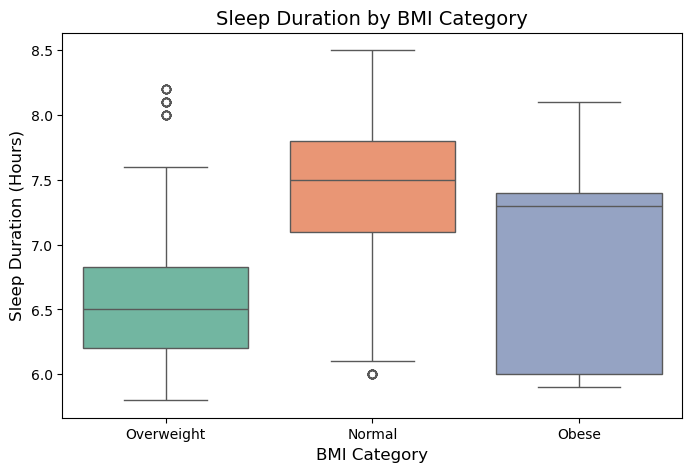

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='BMI Category', y='Sleep Duration', data=df, hue='BMI Category', legend=False, palette='Set2')

plt.title('Sleep Duration by BMI Category', fontsize=14)
plt.xlabel('BMI Category', fontsize=12)
plt.ylabel('Sleep Duration (Hours)', fontsize=12)

plt.show()

## Step 3: Machine Learning Model (Random Forest)
Building a classification model to predict sleep disorders based on physiological and lifestyle metrics.

In [14]:
from sklearn.model_selection import train_test_split

features = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 
            'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic_BP', 'Diastolic_BP']

X = df[features]
y = df['Sleep Disorder'] 

y = y.fillna('None') 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train set size: {X_train.shape[0]} rows")
print(f"Test set size: {X_test.shape[0]} rows")

Train set size: 299 rows
Test set size: 75 rows


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 88.00%

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.95      0.98      0.97        43
    Insomnia       0.72      0.81      0.76        16
 Sleep Apnea       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75



## Project Summary & Research Question

**Project Objective:** To investigate whether lifestyle metrics and physiological data can predict sleep disorders (MedTech domain).

* **Key Insights from Exploratory Data Analysis (EDA):**
  * A clear statistical relationship was found between sleep duration, stress levels, BMI, and the presence of sleep disorders such as Insomnia and Sleep Apnea.
  * Healthy individuals tend to sleep significantly more hours on average and exhibit lower stress levels compared to those with sleep disorders.

* **Machine Learning Model Results:**
  * we trained a **Random Forest** classifier which achieved an impressive overall accuracy of **88%** in predicting sleep disorders on unseen test data.
  * The classification report demonstrates that the model excels at identifying healthy individuals (95% precision) and provides a strong foundation for decision-support systems in healthcare for early risk detection.